# 01 — Human-answer data exploration and fixed splits
**Goal:** understand the human records, clean answer times, and save who and what belongs to training, validation, and testing.

Run Notebook 00 first, then run this notebook from top to bottom. Each plot explains one part of the data. We use **training people and non-final-test images** for the exploration, keeping held-out answer outcomes out of these plots.

Source: [original CIFAR-10H release](https://github.com/jcpeterson/cifar-10h). Its image IDs match the original CIFAR-10 test-image order. In our project we split those 10,000 images again; the original dataset name does not make every image our final test. We download the human records here. Actual image pixels and example image displays will be loaded in Notebook 02 with the feature extractor.

## 1. Load tools and saved settings

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
settings = json.loads((project / 'configs/project_settings.json').read_text())
seed = settings['seed']
raw_folder = project / 'data/cifar10h'
split_folder = project / 'data/splits'
output_folder = project / 'outputs/data_audit'
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    # Keep a copy of every plot for the report.
    plt.tight_layout()
    plt.savefig(output_folder / f'{name}.png', dpi=150)
    plt.show()

## 2. Download and read the records
Download once, then reuse the local file. Each row is one person's answer to one question. We read the CSV directly from the ZIP, so no manual extraction is needed.

In [2]:
source_url = 'https://raw.githubusercontent.com/jcpeterson/cifar-10h/master/data/cifar10h-raw.zip'
archive_path = raw_folder / 'cifar10h-raw.zip'
if not archive_path.exists():
    urlretrieve(source_url, archive_path)
with ZipFile(archive_path) as archive:
    raw_answers = pd.read_csv(archive.open('cifar10h-raw.csv'))
# The release has an extra "test" in this column name; use a shorter name here.
raw_answers = raw_answers.rename(columns={'cifar10_test_test_idx': 'image_id', 'cifar10_test_set_idx': 'image_id'})
print('Rows:', len(raw_answers), '| People:', raw_answers['annotator_id'].nunique())
display(raw_answers.dtypes.rename('type').to_frame())

Rows: 539910 | People: 2571


,type
annotator_id,int64
trial_index,int64
is_attn_check,int64
true_category,str
chosen_category,str
true_label,int64
chosen_label,int64
correct_guess,int64
image_id,int64
image_filename,str


## 3. Check record structure
Attention checks are easy known-answer questions. Their image ID is a special marker, not a normal picture ID. We separate them before splitting normal images. These checks inspect structure; final-test answer quality is not summarized.

In [3]:
attention_answers = raw_answers[raw_answers['is_attn_check'] == 1].copy()
normal_answers = raw_answers[raw_answers['is_attn_check'] == 0].copy()
required = ['annotator_id', 'trial_index', 'image_id', 'true_label', 'chosen_label', 'correct_guess', 'reaction_time']
assert normal_answers[required].notna().all().all()
assert not raw_answers.duplicated(['annotator_id', 'trial_index']).any()
assert normal_answers['image_id'].between(0, 9999).all()
assert normal_answers.groupby('image_id')['true_label'].nunique().eq(1).all()
assert normal_answers['true_label'].between(0, 9).all()
assert normal_answers['chosen_label'].between(0, 9).all()
assert normal_answers['correct_guess'].eq(normal_answers['true_label'].eq(normal_answers['chosen_label']).astype(int)).all()
print('Normal trials:', len(normal_answers), '| Attention checks:', len(attention_answers))
print('Normal images:', normal_answers['image_id'].nunique())

Normal trials: 514200 | Attention checks: 25710
Normal images: 10000


## 4. Freeze the people split
Training people help build the system. Validation people help choose settings. Test people are held back for reporting. A person belongs to exactly one group. Whole people are separated, not random rows from the same person.

In [4]:
people = np.sort(raw_answers['annotator_id'].unique())
people = np.random.default_rng(seed).permutation(people)
train_end = int(len(people) * settings['annotator_fractions']['train'])
validation_end = train_end + int(len(people) * settings['annotator_fractions']['validation'])
people_split = pd.DataFrame({'annotator_id': people, 'annotator_split':
    ['train'] * train_end + ['validation'] * (validation_end - train_end) + ['test'] * (len(people) - validation_end)})
people_path = split_folder / 'annotators.csv'
if people_path.exists():
    pd.testing.assert_frame_equal(pd.read_csv(people_path), people_split)
else:
    people_split.to_csv(people_path, index=False)
display(people_split['annotator_split'].value_counts().rename('people').to_frame())

,people
annotator_split,
train,1542
test,515
validation,514


## 5. Freeze the image split
Each class contributes 400 pool, 200 difficulty-training, 200 validation, and 200 final-test images. This is **stratification**: keeping equal class representation in every group. Only image IDs and category labels are used to create this split, not human success rates.

The 2,000 difficulty-training images are separate from the active-learning pool. Validation images can later be divided for calibration/model selection as needed.

In [5]:
image_info = normal_answers[['image_id', 'true_label', 'true_category']].drop_duplicates().sort_values('image_id')
assert len(image_info) == 10000
random = np.random.default_rng(seed)
image_groups = []
for class_id, class_images in image_info.groupby('true_label'):
    image_ids = random.permutation(class_images['image_id'].to_numpy())
    start = 0
    for split_name, count in settings['image_counts_per_class'].items():
        image_groups.append(pd.DataFrame({'image_id': image_ids[start:start + count], 'image_split': split_name}))
        start += count
    assert start == len(image_ids)
image_split = image_info.merge(pd.concat(image_groups), on='image_id', validate='one_to_one').sort_values('image_id').reset_index(drop=True)
image_path = split_folder / 'images.csv'
if image_path.exists():
    pd.testing.assert_frame_equal(pd.read_csv(image_path), image_split)
else:
    image_split.to_csv(image_path, index=False)
assert image_split['image_id'].is_unique
assert image_split['image_split'].eq('final_test').sum() == 2000
print('Saved fixed splits. A rerun checks them rather than silently replacing them.')

Saved fixed splits. A rerun checks them rather than silently replacing them.


## 6. See the split sizes
The class bars should match across categories. These are counts, not performance measurements.

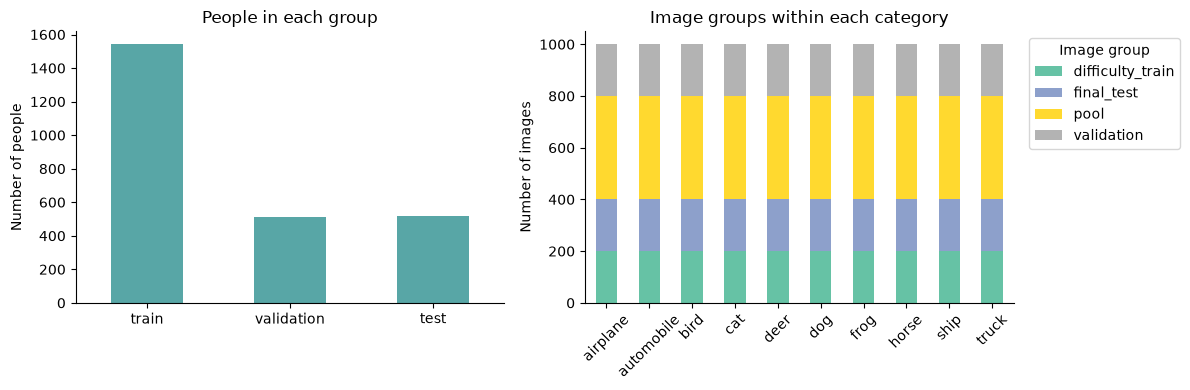

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
people_split['annotator_split'].value_counts().reindex(['train', 'validation', 'test']).plot.bar(ax=axes[0], color='#58a6a6')
axes[0].set(title='People in each group', ylabel='Number of people', xlabel='')
image_counts = pd.crosstab(image_split['true_category'], image_split['image_split'])
image_counts.plot.bar(stacked=True, ax=axes[1], colormap='Set2')
axes[1].set(title='Image groups within each category', ylabel='Number of images', xlabel='')
axes[1].legend(title='Image group', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='x', rotation=45)
show_plot('01_people_and_image_splits')

## 7. Select development records and clean time
All remaining exploration uses training people and non-final-test images only.

Clip means replace times below 0.2 seconds with 0.2, and above 30 seconds with 30. Keep the original milliseconds too. Clipping is a cleaning convention, not evidence that a negative recorded time was a real fast answer.

In [7]:
development_people = people_split.loc[people_split['annotator_split'] == 'train', 'annotator_id']
development_images = image_split.loc[image_split['image_split'] != 'final_test', 'image_id']
answers = normal_answers[normal_answers['annotator_id'].isin(development_people) & normal_answers['image_id'].isin(development_images)].copy()
low_ms, high_ms = settings['reaction_time_limits_ms']
answers['response_seconds'] = answers['reaction_time'].clip(low_ms, high_ms) / 1000
answers['time_was_clipped'] = ~answers['reaction_time'].between(low_ms, high_ms)
assert not answers['image_id'].isin(image_split.loc[image_split['image_split'] == 'final_test', 'image_id']).any()
assert set(answers['annotator_id']).issubset(set(development_people))
summary = pd.Series({'development_answers': len(answers), 'training_people': answers['annotator_id'].nunique(),
    'development_images': answers['image_id'].nunique(), 'accuracy_percent': answers['correct_guess'].mean() * 100,
    'median_response_seconds': answers['response_seconds'].median(), 'clipped_times': int(answers['time_was_clipped'].sum())})
display(summary.to_frame('value'))
display(answers[['annotator_id', 'trial_index', 'image_id', 'true_category', 'chosen_category', 'correct_guess', 'response_seconds']].head())

,value
development_answers,246895.000000
training_people,1542.000000
development_images,8000.000000
accuracy_percent,94.911602
median_response_seconds,1.490000
clipped_times,190.000000


,annotator_id,trial_index,image_id,true_category,chosen_category,correct_guess,response_seconds
0,0,0,6798,ship,ship,1,1.342
1,0,1,1118,deer,horse,0,4.305
4,0,4,373,deer,bird,0,4.410
5,0,5,733,truck,truck,1,1.657
6,0,6,3441,airplane,airplane,1,1.486


## 8. How accurate are people on each category?
Lower bars mean more mistakes. Differences can reflect both image difficulty and people.

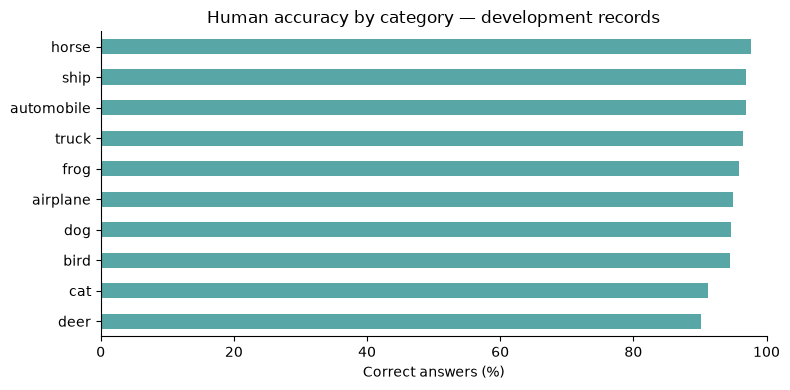

In [8]:
class_accuracy = answers.groupby('true_category')['correct_guess'].mean().sort_values() * 100
class_accuracy.plot.barh(color='#58a6a6')
plt.xlabel('Correct answers (%)')
plt.xlim(0, 100)
plt.ylabel('')
plt.title('Human accuracy by category — development records')
show_plot('02_accuracy_by_category')

## 9. Do all people perform equally well?
Each value below summarizes one training person, using their available development images. This shows variation; it is not yet a difficulty-adjusted skill estimate.

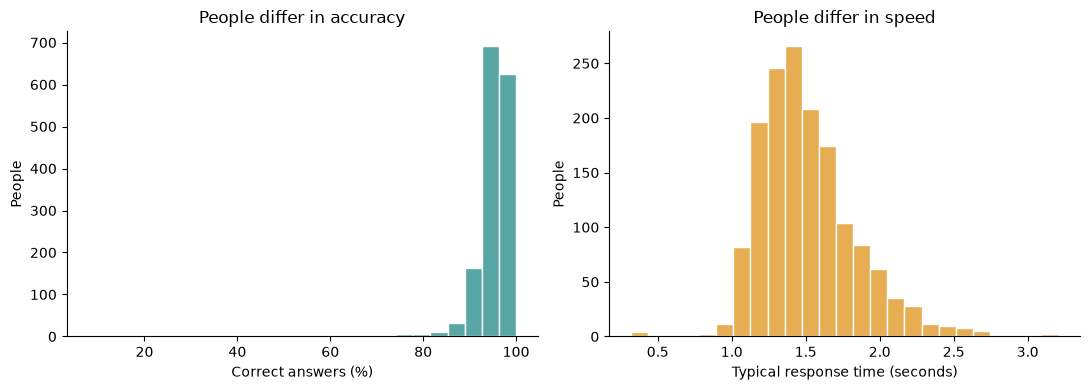

In [9]:
person_summary = answers.groupby('annotator_id').agg(accuracy=('correct_guess', 'mean'),
    median_seconds=('response_seconds', 'median'), answers=('correct_guess', 'size'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(person_summary['accuracy'] * 100, bins=25, color='#58a6a6', edgecolor='white')
axes[0].set(title='People differ in accuracy', xlabel='Correct answers (%)', ylabel='People')
axes[1].hist(person_summary['median_seconds'], bins=25, color='#e7ad52', edgecolor='white')
axes[1].set(title='People differ in speed', xlabel='Typical response time (seconds)', ylabel='People')
show_plot('03_people_accuracy_and_speed')

## 10. How long do answers take?
The right plot zooms into 10 seconds so the common response times are readable. Long pauses still remain in the saved cleaned data, capped at 30 seconds.

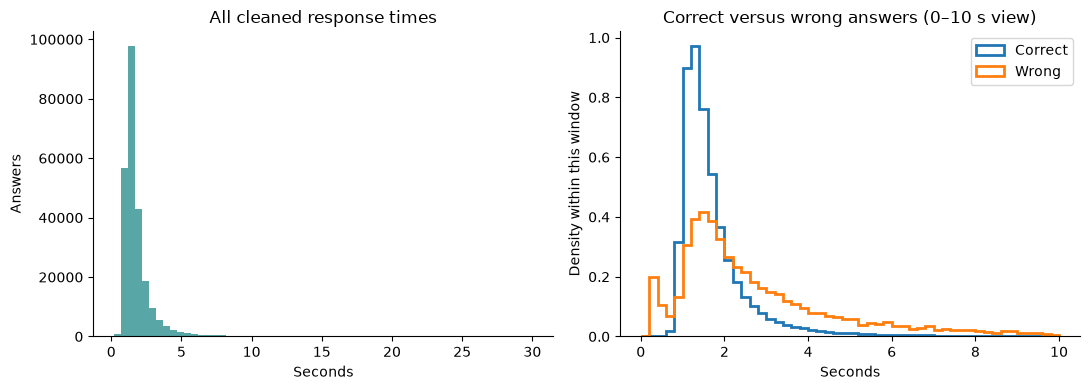

,median seconds
correct_guess,
Wrong,2.214
Correct,1.474


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(answers['response_seconds'], bins=60, color='#58a6a6')
axes[0].set(title='All cleaned response times', xlabel='Seconds', ylabel='Answers')
for correct, label in [(1, 'Correct'), (0, 'Wrong')]:
    times = answers.loc[answers['correct_guess'] == correct, 'response_seconds']
    axes[1].hist(times, bins=np.linspace(0, 10, 51), density=True, histtype='step', linewidth=2, label=label)
axes[1].set(title='Correct versus wrong answers (0–10 s view)', xlabel='Seconds', ylabel='Density within this window')
axes[1].legend()
show_plot('04_response_time_distributions')
display(answers.groupby('correct_guess')['response_seconds'].median().rename(index={0: 'Wrong', 1: 'Correct'}).to_frame('median seconds'))

## 11. Which pictures are hard for people?
Estimate correctness using `(correct answers + 0.5) / (answers + 1)`. The extra small counts avoid pretending we know a picture is always answered correctly. This is a **shrunk estimate**: a slightly cautious success rate.

Higher `d_x` actually means **easier**. We save both an easy-to-read hard-picture score and `d_x` for later equations. These are development-data descriptions, not predictions available to a controller.

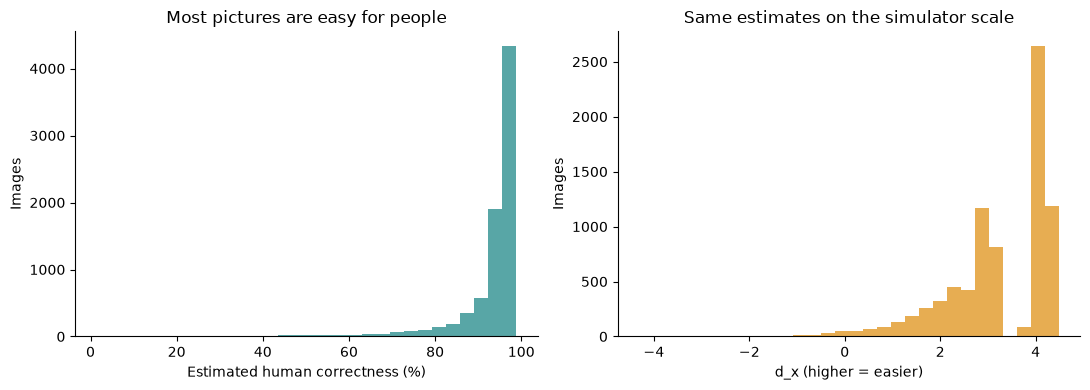

In [15]:
image_summary = answers.groupby('image_id')['correct_guess'].agg(correct='sum', answers='size')
image_summary['human_success'] = (image_summary['correct'] + 0.5) / (image_summary['answers'] + 1)
image_summary['hard_picture_score'] = 1 - image_summary['human_success']
image_summary['d_x'] = np.log(image_summary['human_success'] / (1 - image_summary['human_success']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(image_summary['human_success'] * 100, bins=30, color='#58a6a6')
axes[0].set(title='Most pictures are easy for people', xlabel='Estimated human correctness (%)', ylabel='Images')
axes[1].hist(image_summary['d_x'], bins=30, color='#e7ad52')
axes[1].set(title='Same estimates on the simulator scale', xlabel='d_x (higher = easier)', ylabel='Images')
show_plot('05_image_difficulty')

## 12. Which categories get confused?
Each row is the real category. Each column is the answer given. We hide the correct-answer diagonal to make mistakes visible. Values are percentages of **all answers for that real category**, not just mistakes.

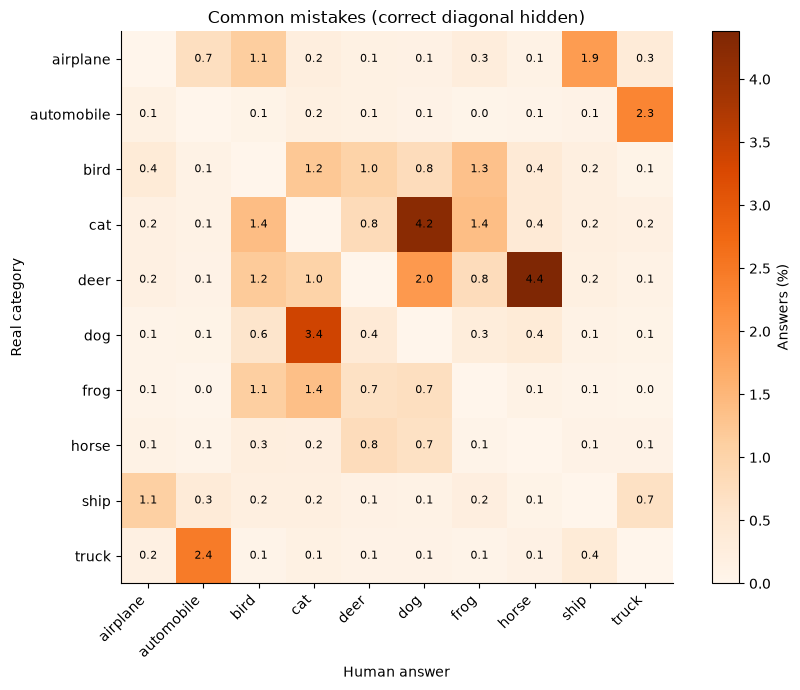

In [17]:
class_names = image_info.sort_values('true_label').drop_duplicates('true_label')['true_category'].tolist()
confusion = pd.crosstab(answers['true_category'], answers['chosen_category'], normalize='index').reindex(index=class_names, columns=class_names, fill_value=0) * 100
error_confusion = confusion.copy()
error_confusion.iloc[range(min(error_confusion.shape)), range(min(error_confusion.shape))] = 0
fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(error_confusion, cmap='Oranges')
ax.set_xticks(range(10), class_names, rotation=45, ha='right')
ax.set_yticks(range(10), class_names)
for row in range(10):
    for column in range(10):
        if row != column:
            ax.text(column, row, f'{error_confusion.iloc[row, column]:.1f}', ha='center', va='center', fontsize=8)
ax.set(xlabel='Human answer', ylabel='Real category', title='Common mistakes (correct diagonal hidden)')
fig.colorbar(heatmap, ax=ax, label='Answers (%)')
show_plot('06_confusion_heatmap')

## 13. What changes during a session?
Group questions into blocks of 20 original trial positions. Attention checks have been removed, but the original order is preserved. This avoids inventing a new time axis. Raw changes alone do not prove fatigue: picture difficulty and practice also matter. The accuracy axis is zoomed in to show small changes; check the tick values before interpreting a drop.

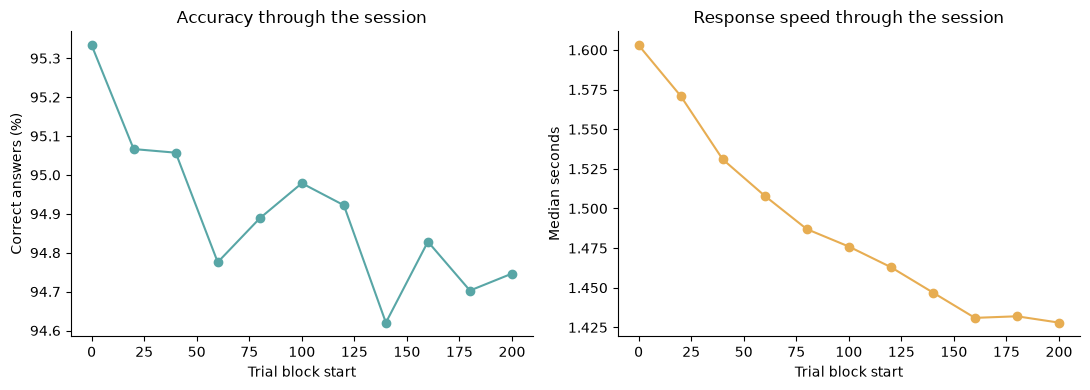

In [18]:
answers['trial_block'] = (answers['trial_index'] // 20) * 20
session_summary = answers.groupby('trial_block').agg(accuracy=('correct_guess', 'mean'),
    median_seconds=('response_seconds', 'median'), answers=('correct_guess', 'size'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(session_summary.index, session_summary['accuracy'] * 100, 'o-', color='#58a6a6')
axes[0].set(title='Accuracy through the session', xlabel='Trial block start', ylabel='Correct answers (%)')
axes[1].plot(session_summary.index, session_summary['median_seconds'], 'o-', color='#e7ad52')
axes[1].set(title='Response speed through the session', xlabel='Trial block start', ylabel='Median seconds')
show_plot('07_accuracy_and_time_over_session')

## 14. Account for picture difficulty before looking for drift
For each answer, estimate that picture's success rate from the **other training people's answers**, then subtract it from this answer's correctness. A residual near zero means roughly the expected performance for that picture. Leaving this person's answer out avoids comparing an answer partly with itself.

This simple descriptive check is not a causal fatigue test or the final skill model. Our brief full-dataset analysis found no average fatigue; our subset can fluctuate.

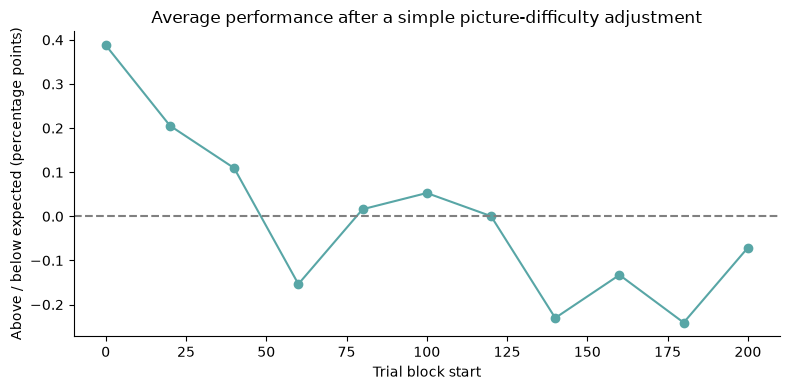

,residual percentage points
trial_block,
0,0.387916
20,0.205538
40,0.109335
60,-0.153496
80,0.016091
100,0.052892
120,0.000468
140,-0.230352
160,-0.132803


In [19]:
answers = answers.join(image_summary[['correct', 'answers']], on='image_id')
assert answers['answers'].gt(1).all(), 'Each picture needs at least two answers for this check.'
other_success = (answers['correct'] - answers['correct_guess']) / (answers['answers'] - 1)
answers['difficulty_residual'] = answers['correct_guess'] - other_success
adjusted = answers.groupby('trial_block')['difficulty_residual'].mean() * 100
adjusted.plot(marker='o', color='#58a6a6')
plt.axhline(0, color='gray', linestyle='--')
plt.title('Average performance after a simple picture-difficulty adjustment')
plt.xlabel('Trial block start')
plt.ylabel('Above / below expected (percentage points)')
show_plot('08_difficulty_adjusted_session_pattern')
display(adjusted.rename('residual percentage points').to_frame())

## 15. Check the known-answer questions separately
These answers belong to training people only. They are not mixed into image difficulty. Later, simulated gold checks provide clues about attention and fatigue.

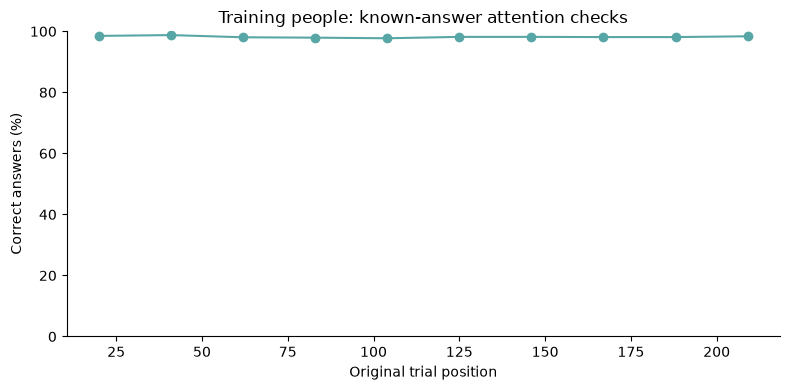

In [20]:
training_checks = attention_answers[attention_answers['annotator_id'].isin(development_people)]
check_accuracy = training_checks.groupby('trial_index')['correct_guess'].mean() * 100
check_accuracy.plot(marker='o', color='#58a6a6')
plt.ylim(0, 100)
plt.title('Training people: known-answer attention checks')
plt.xlabel('Original trial position')
plt.ylabel('Correct answers (%)')
show_plot('09_attention_checks')

## 16. Save what the next notebooks need
The cleaned CSV contains only the development records explored here. Held-out records stay in the raw archive and are accessed later under their saved split assignments. The audit image table must never be fed directly to the controller as true difficulty. Later we train a predictor on the separate difficulty-training images. A file fingerprint identifies the exact input used; it is not a security check.

In [21]:
processed_folder = project / 'data/processed'
answers.to_csv(processed_folder / 'development_answers.csv.gz', index=False)
image_summary.to_csv(processed_folder / 'development_image_summary.csv')
person_summary.to_csv(processed_folder / 'development_person_summary.csv')
confusion.to_csv(processed_folder / 'development_confusion_percent.csv')
summary.to_json(output_folder / 'summary.json', indent=2)
provenance = {'source': source_url, 'archive_sha256': hashlib.sha256(archive_path.read_bytes()).hexdigest(),
    'seed': seed, 'exploration_scope': 'training annotators and non-final-test images',
    'split_origin': settings['split_origin'], 'image_pixels_loaded': False,
    'settings': settings}
(output_folder / 'data_provenance.json').write_text(json.dumps(provenance, indent=2))
print('Saved cleaned development records, fixed splits, summaries, provenance, and 9 plot files.')

Saved cleaned development records, fixed splits, summaries, provenance, and 9 plot files.


## 17. Summary:
- We downloaded actual human answers, not invented data.
- We separated people and images before exploring answer quality.
- People differ in speed and accuracy; pictures differ in difficulty.
- Wrong-answer patterns help us build a realistic simulated teacher.
- A session trend alone does not prove fatigue. We will include the zero-fatigue world.
- We created a new reproducible split because the old split file was unavailable.

**Still to do:** load actual images and check their category/ID alignment in Notebook 02; build the picture learner; estimate the full simulator's skill and response-time parameters; and validate the simulator. The descriptive summaries here do not replace those steps.

**Next notebook:** `02_image_features_and_classifier.ipynb`.